# Meshing

This notebook is used to develop the regional mesh for salinity transport.

- Efficiently read in a fort.14 file
- Filter the mesh to the sub-region of interest.
- Preserve boundary segments for use in the FEniCSx solver.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import adcircxtools as at
import adios4dolfinx as adx
import basix.ufl
import cmocean
import dolfinx as dx
import dolfinx.plot
from mpi4py import MPI
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri
import matplotlib.path
import pyvista as pv
import scipy.interpolate
import scipy.spatial
import ufl

## Read in fort.14

In [3]:
adcirc_mesh = at.mesh.ADCIRCMesh.from_fort_14('fort.14')
mesh = at.mesh.Mesh.from_ADCIRCMesh(adcirc_mesh)

## Filter to desired subregion

Here we filter the mesh to a longitude-latitude polygon around Port Aransas. A second larger polygon is used for the ADCIRC data interpolation region, since numerical imprecisions lead to salinity mesh nodes falling slightly outside ADCIRC mesh nodes.

Filtering the mesh by coordinates is a class method of the `Mesh` object and consists of three stages.

1. Determine which nodes are in the `True` region.
2. Filter elements whose every node are in this region.
3. Filter nodes again, making sure that they are attached to at least one element in the region.

In [4]:
# Define the polygon and filter callable
points_main = np.array([
    [-97.0, 27.0],
    [-98.0, 27.0],
    [-98.0, 28.0],
    [-96.5, 29.0],
    [-95.5, 29.0],
    [-95.5, 28.0]
])
polygon_main = matplotlib.path.Path(points_main)
filter_main = lambda lon, lat: polygon_main.contains_points(
    np.column_stack((lon, lat))
)

In [5]:
# Filter mesh for salinity model
mesh_main, node_map_main, element_map_main = mesh.filter_by_coordinates(filter_main)

In [6]:
# Define a larger polygon and filter callable
points_interp = np.array([
    [-96.9, 26.9],
    [-98.1, 26.9],
    [-98.1, 28.1],
    [-96.6, 29.1],
    [-95.4, 29.1],
    [-95.4, 27.9]
])
polygon_interp = matplotlib.path.Path(points_interp)
filter_interp = lambda lon, lat: polygon_interp.contains_points(
    np.column_stack((lon, lat))
)

In [7]:
# Filter mesh for ADCIRC data interpolation
mesh_interp, node_map_interp, element_map_interp = mesh.filter_by_coordinates(filter_interp)

In [8]:
# Define triangulation for interpolation and visualization
triangulation_main = matplotlib.tri.Triangulation(
    mesh_main.coordinates[:, 0],
    mesh_main.coordinates[:, 1],
    mesh_main.elements
)

In [9]:
# Define triangulation for interpolation and visualization
triangulation_interp = matplotlib.tri.Triangulation(
    mesh_interp.coordinates[:, 0],
    mesh_interp.coordinates[:, 1],
    mesh_interp.elements
)

## Create FEniCSx mesh

In [10]:
# Define simple triangular mesh from the coordinates and elements
ufl_tri = ufl.Mesh(basix.ufl.element('Lagrange', 'triangle', 1, shape=(2,)))
domain = dx.mesh.create_mesh(
    MPI.COMM_WORLD,
    cells=mesh_main.elements,
    x=mesh_main.coordinates,
    e=ufl_tri
)

## Create bathymetry function

In [11]:
# Set up interpolation function for bathymetry
bathymetry_interpolator = matplotlib.tri.LinearTriInterpolator(
    triangulation_interp,
    adcirc_mesh.DP[node_map_interp != -1]
)
def bathy(x):
    return bathymetry_interpolator(x[0], x[1])

In [12]:
# Create continuous linear bathymetry function
V = dx.fem.functionspace(domain, ('Lagrange', 1))
dp = dx.fem.Function(V, name='dp')
dp.interpolate(bathy)

## Create initial condition

For now, a constant concentration $c = 1$ is assumed.

In [13]:
def iota0(x):
    return np.maximum(bathymetry_interpolator(x[0], x[1]), 0.0)
W = dx.fem.functionspace(domain, ('Discontinuous Lagrange', 1))
iota = dx.fem.Function(W, name='iota') # Depends on solution method
iota.interpolate(iota0)

## Visualization

Here, we want to make sure that the solution mesh is reasonable, and the interpolation mesh is larger than the solution mesh. Plots are saved for presentations and publications.

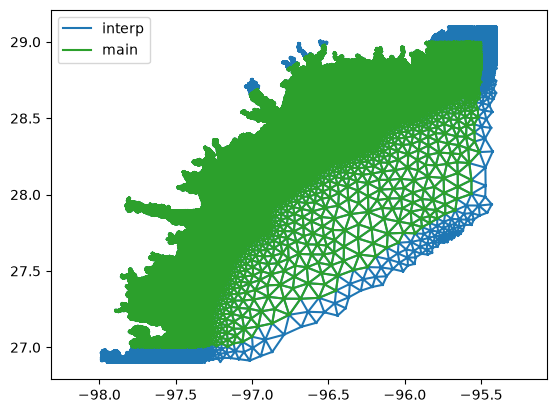

In [14]:
# Check that the interpolataion mesh has a margin around the main mesh
fig, ax = plt.subplots()
ax.triplot(triangulation_interp, label='interp')
ax.triplot(triangulation_main, label='main')
ax.legend()
ax.set_aspect('equal', adjustable='datalim')

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


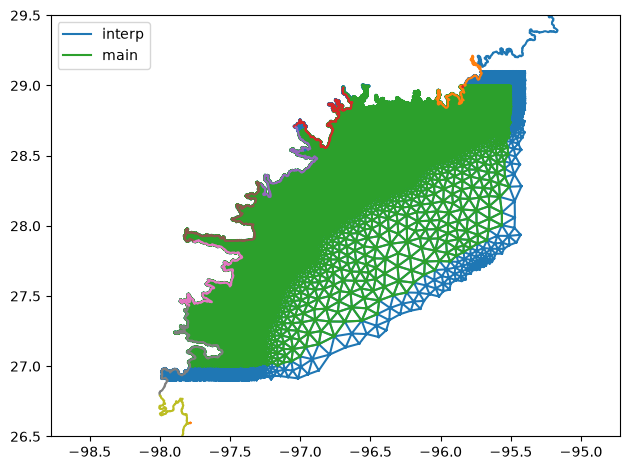

In [15]:
# Show mesh boundaries as well
# None intersect with the study area
fig, ax = plt.subplots()
ax.triplot(triangulation_interp, label='interp')
ax.triplot(triangulation_main, label='main')
ax.legend()
ax.set_aspect('equal', adjustable='datalim')
for k in range(adcirc_mesh.NOPE):
    ax.plot(
        adcirc_mesh.X[adcirc_mesh.NBDV[k] - 1],
        adcirc_mesh.Y[adcirc_mesh.NBDV[k] - 1],
        color='r'
    )
for k in range(adcirc_mesh.NBOU):
    ax.plot(
        adcirc_mesh.X[adcirc_mesh.NBVV[k] - 1],
        adcirc_mesh.Y[adcirc_mesh.NBVV[k] - 1]
    )
ax.set_xlim((-98.5, -95.0))
ax.set_ylim((26.5, 29.5))
ax.set_aspect('equal')
fig.tight_layout()
fig.savefig('tracer_mesh.png')

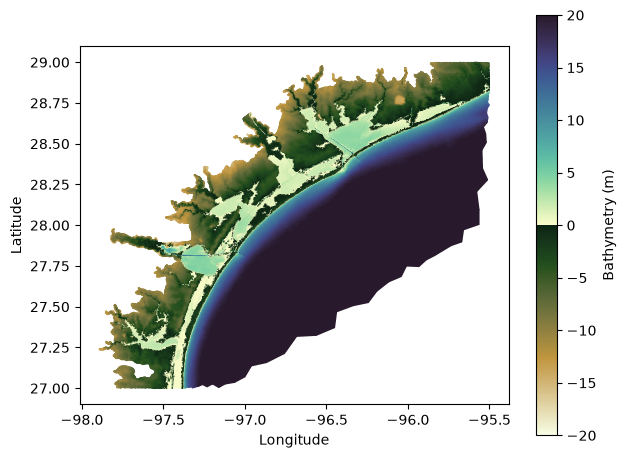

In [16]:
# Show bathymetry
# Check that the interpolataion mesh has a margin around the main mesh
fig, ax = plt.subplots()
tpc = ax.tripcolor(
    triangulation_main,
    adcirc_mesh.DP[node_map_main != -1],
    shading='gouraud',
    cmap=cmocean.cm.topo.reversed(),
    vmin=-20.0,
    vmax=20.0
)
fig.colorbar(tpc, ax=ax, label='Bathymetry (m)')
ax.set_aspect('equal')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
fig.tight_layout()
fig.savefig('tracer_bathy.png')

## Save all data structures

In [17]:
adx.write_mesh('texas_coast.bp', domain)

In [18]:
adx.write_function('texas_coast.bp', dp)
adx.write_function('texas_coast.bp', iota)
el = iota.function_space.ufl_element() # Write function space info
adx.write_attributes('texas_coast.bp', MPI.COMM_WORLD, 'iota_element', {
    'family': np.array([el.basix_element.family.value], dtype=np.int32),
    'degree': np.array([el.degree], dtype=np.int32),
    'discontinuous': np.array([el.discontinuous], dtype=np.int32),
    'shape': np.array(el.reference_value_shape or (1,), dtype=np.int32),
})

In [19]:
np.save('main_coordinates.npy', mesh_main.coordinates)
np.save('main_elements.npy', mesh_main.elements)
np.save('main_node_map.npy', node_map_main)
np.save('main_element_map.npy', element_map_main)
np.save('interp_coordinates.npy', mesh_interp.coordinates)
np.save('interp_elements.npy', mesh_interp.elements)
np.save('interp_node_map.npy', node_map_interp)
np.save('interp_element_map.npy', element_map_interp)